In [1]:
""" 
We are building a State Graph. It has two main nodes:

    The Agent: Decides if it needs to use a tool.

    The Tool Extractor: Executes the tool and feeds the result back to the agent


    tavily-python (it's free for a good amount of searches).
""";

In [2]:
import os
from typing import Annotated, TypedDict
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_community.tools.tavily_search import TavilySearchResults
from langgraph.graph import StateGraph, END
from langgraph.prebuilt import ToolNode
from langchain_core.messages import BaseMessage



/tmp/ipykernel_65656/1337989790.py:4: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools.tavily_search import TavilySearchResults


In [3]:
# Define the State
from langgraph.graph.message import add_messages

class State(TypedDict):
    # 'add_messages' is the glue that keeps the history alive
    messages: Annotated[list[BaseMessage], add_messages]



In [4]:
from dotenv import load_dotenv
load_dotenv() 

True

In [5]:
# 1. Initialize Gemini 3.1 Flash-Lite
# Note: Ensure GOOGLE_API_KEY is in your environment variables
llm = ChatGoogleGenerativeAI(
    model="gemini-3.1-flash-lite",
    temperature=0,
    max_output_tokens=50  
)



Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.


In [6]:
# 2. Setup Tools
search_tool = TavilySearchResults(max_results=2)
tools = [search_tool]
tool_node = ToolNode(tools)

# 3. Bind tools to Gemini
# Force Gemini to use a tool
llm_with_tools = llm.bind_tools(
    tools, 
    # tool_choice="any" # This forces the model to pick a tool from your list
)

# TAVILY_API_KEY

/tmp/ipykernel_65656/20675832.py:2: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  search_tool = TavilySearchResults(max_results=2)


In [7]:
# --- Graph Nodes ---

def call_model(state: State):
    response = llm_with_tools.invoke(state['messages'])
    return {"messages": [response]}

def should_continue(state: State):
    last_message = state['messages'][-1]
    if last_message.tool_calls:
        return "tools"
    return END



In [8]:
# --- Build the Graph ---

workflow = StateGraph(State)

workflow.add_node("agent", call_model)
workflow.add_node("tools", tool_node)

workflow.set_entry_point("agent")
workflow.add_conditional_edges("agent", should_continue)
workflow.add_edge("tools", "agent")

In [9]:
app = workflow.compile()

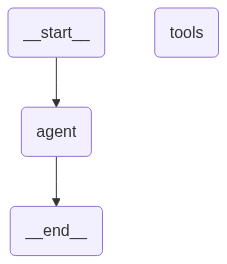

In [10]:
app

In [11]:
from langchain_core.messages import HumanMessage, SystemMessage

system_msg = SystemMessage(content=(
    "You are a helpful assistant with access to a real-time web search tool. "
    "If you don't know an answer (like the weather or current events), "
    "ALWAYS use the search tool. Do not say you cannot help; use your tools instead."
))

inputs = {
    "messages": [
        system_msg, 
        HumanMessage(content="What is the current weather in Nashik?")
    ]
}

for output in app.stream(inputs):
    print(output)

{'agent': {'messages': [AIMessage(content=[], additional_kwargs={'function_call': {'name': 'tavily_search_results_json', 'arguments': '{"query": "current weather in Nashik"}'}, '__gemini_function_call_thought_signatures__': {'call_3138723': 'EnMKcQFpFH0T0DR59ozVibJv4Kj1onuA/Elzd+WiDvwdWOJDqTmjZ+n2D8emPRitL51jXPcnzBGYrykVInsu/IUBFXatFwSuKHVLqlGZIG5J1mgld7sJ5BPGlz3zngaE2uGvORwkydcGnDfrQgTiXt3XMHwV'}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.1-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1805c-b4b2-7ab0-8065-3de51586b66f-0', tool_calls=[{'name': 'tavily_search_results_json', 'args': {'query': 'current weather in Nashik'}, 'id': 'call_3138723', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 145, 'output_tokens': 26, 'total_tokens': 171, 'input_token_details': {'cache_read': 0}})]}}


{'tools': {'messages': [ToolMessage(content='[{"title": "Nashik Weather Forecast Wednesday, 28 October 2026", "url": "https://www.ndtv.com/weather/nashik-weather-forecast-today", "content": "Today\'s weather forecast in Nashik is Overall clear sky. High 34°C, Low 18°C . Currently 19°C. Stay updated for accurate weather information in Nashik.", "score": 0.964298}, {"title": "Nashik Weather Conditions: Temperature | 30 Days Forecast", "url": "https://www.aqi.in/weather/us/india/maharashtra/nashik", "content": "From 03:30 PM 24 October 2026, Nashik\'s 10-day forecast shows this trend: Today (Oct. 24) : Temp. 26°C, Hum. 50% and Smoky haze condition. Sunday (Oct. 25) : Temp. 26°C, Hum. 46% and Smoky haze condition. Monday (Oct. 26) : Temp. 25°C, Hum. 37% and Sunny condition. Tuesday (Oct. 27) : Temp. 24°C, Hum. 38% and Sunny condition. Wednesday (Oct. 28) : Temp. 23°C, Hum. 34% and Overcast condition. Thursday (Oct. 29) : Temp. 24°C, Hum. 38% and Overcast condition. Friday (Oct. 30) : Temp.

{'agent': {'messages': [AIMessage(content=[{'type': 'text', 'text': "The current weather in Nashik is clear with a temperature of 19°C. Today's forecast indicates a high of 34°C and a low of 18°C.", 'extras': {'signature': 'EnMKcQFpFH0Tt2GBvB03U4+swvnN8R+MgF40Al+HG3tRlzPQlALHuUlXyZ0ZOp07YY01C1/sWL2eF9QyKrysQJHE9u7gVCew+YcWpQKNtZdJi9FGu6hVfULiae/CMmTbpyCh74LRG5Q5ETChFYHgt4MBcJxo'}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.1-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1805c-bccd-70c0-8b75-2c55a07bbdbe-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1245, 'output_tokens': 41, 'total_tokens': 1286, 'input_token_details': {'cache_read': 0}})]}}
